# <a id='Index'>Photoreceptor arrays</a>
- [Voronoi](#voronoi)
- [NDD](#ndd)
- [Batch analysis](#batch)
- [Distribution models???](#models)

Ideas:
- Use kNDD and bound it by theoretical hex lattice and random distributions (bootstrapped à la JohnBall)
- Use pairwise NDD within all subtypes? Are there exclusion zones between pairs?

To do:
- [x] visualisation for single example
    - [x] Voronoi
    - [x] Llloyd's algorithm + bounding box
    - [ ] Should rewrite Lloyd's implementation to use scipy.spatial functions (findCentroid) and to bound search withing box properly
    - [ ] random distribution (should I account for physical size of cones?)
    - [x] support for tiff loading
    - [x] single class that allows flexible inputs to run in any photoreceptor subtype (based on napari segmentation or points)
- [x] batch analysis
    - [x] NDD distribution for each image
    - [x] NDDi distribution after Lloyd's relaxation (and final point distribution)
    - [x] summary bot to collect medians and to create meta-distributions by genotype
- [ ] integrate into napari
    - [ ] calculate and display Voronoi: might be easiest to calculate and then transform to a labels layer: [codehere](https://napari.org/stable/gallery/shapes_to_labels.html)
    - [ ] run by default as a final step during curation of segmentation AND to help with dotting.
        - need to revise analysis of UV cones and where possible merge U_missing.csv and U_seg_curated.tiff into a single U_points.csv
    - [ ] Animation of Lloyd's algorithm could be fun. Could be set up as a z-stack initially

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from scipy.stats import sem
from scipy import stats as st 
import scikit_posthocs
import scipy.spatial
import math
import IPython
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import colorsys
import importlib
import svgutils
from svgutils.compose import *
import os.path
import time, sys, warnings
from tqdm.notebook import tqdm, trange
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal
from skimage.io import imread
import ipywidgets
from IPython.display import display
from plotParams import *
from lloyd import *


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [2]:
# baseColor = applyPlotStyle(pBGMenu.value)
# p2um = 63.64/1024


## Debugging code

In [2]:
class NNDcalculator():
    '''
    Calculates NND (nearest-neighbour distances) and idealized NND (after running Lloyd's algorithm) using napari points or labels layer
    Created by Angueyra (Jan 2023)
    '''

    def __init__(self, dPath = '', celltype = 'U', datatype = 'points', nIter = 20, saveLloyd = False, overwriteFlag = False, **kwargs):
        '''
        descriptionHere
        '''
        self.dPath = dPath
        self.celltype = celltype
        self.datatype = datatype
        if (datatype=='labels'):
            self.fPath = self.celltype + '_seg_curated.tiff'
        elif (datatype=='points'):
            if (self.celltype=='U'):
                self.fPath = 'U_missing.csv'
            else:
                self.fPath = self.celltype + '_points.csv'
        self.ifPath = self.celltype + '_lloyd.npy'
        self.N_mip = 'N_mip.tiff'
        self.p2um = 79.80/2048
        self.kN = 1
        self.nIter = nIter
        self.Centroids = self.getCentroids();
        if (np.size(self.Centroids)>0): # skip any calculations if filepath is empty
            self.vor = scipy.spatial.Voronoi(self.Centroids)
            self.kdt = scipy.spatial.KDTree(self.Centroids)
            self.nnd = self.calcNND()
            self.iCentroids = self.calcLloyd(nIter = self.nIter, overwriteFlag = overwriteFlag)
            self.ivor = scipy.spatial.Voronoi(self.iCentroids)
            self.ikdt = scipy.spatial.KDTree(self.iCentroids)
            self.innd = self.calcNNDi()
            if saveLloyd:
                self.saveLloyd()
        
    def getCentroids(self):
        # return empty array if file does not exist
        if (os.path.isfile(self.dPath + self.fPath)==False):
            warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
            Centroids = [];
        else:
            if (self.datatype=='points'): # assumes input is structured like a napari points layer
                df =  pd.read_csv(self.dPath + self.fPath)
                df = df.drop(columns = 'index')
                Centroids = df.to_numpy()
                Centroids = Centroids[:,[1,0]]
            elif(self.datatype=='labels'): # input is an image file akin to napari labels layer
                labelData = imread (self.dPath + self.fPath)
                Centroids = calculateCentroidsFromLabels(labelData)
        return Centroids
        
    def calcNND(self):
        nnd = self.findNND(self.Centroids, self.kdt, self.kN)
        return nnd

    def calcNNDi(self):
        nndi = self.findNND(self.iCentroids, self.ikdt, self.kN)
        return nndi
    
    @staticmethod
    def findNND(centroids, kdt, kN):
        # initialize emtpy arrays
        nnd = np.empty((len(centroids),kN))
        nnd[:]=np.NaN
        # find k nearest neighbor distances
        for n in range(0,len(centroids)):
            temp = kdt.query(centroids[n],kN+1)
            for k in range (0,kN):
                nnd[n,k] = temp[0][k+1]
        return nnd

    
    def calcLloyd(self,nIter=20, overwriteFlag = False):
        if ((os.path.isfile(self.dPath + self.ifPath)) & (overwriteFlag == False)):
            print('Loaded saved Lloyd relaxation')
            iCentroids = np.load(self.dPath + self.ifPath, allow_pickle=True)
        else:
            #start from original locations
            field = Field(self.Centroids, buffer = 20) 
            # # #start from center of the field
            # rng = np.random.default_rng()
            # rndCentroids = rng.integers(500,525, size=np.shape(self.Centroids))
            # field = Field(rndCentroids, buffer = 20) 
            with tqdm(total=nIter, file=sys.stdout) as progBar:
            # run Lloyd relaxation on the field of points
                for i in np.arange(0,nIter):
                    field.relax()
                    progBar.update(1)
            # get the resulting point positions
            iCentroids = field.get_points()
        return iCentroids
    
    def saveLloyd(self):
        np.save(self.dPath + self.ifPath, self.iCentroids)
        np.save(self.dPath + 'nnd.npy', self.nnd)
        np.save(self.dPath + 'innd.npy', self.innd)
        print('Saved results for {0}'.format(self.dPath))
    
    def plotAll(self):
        fH, axH = plt.subplots(2, 2, figsize= [24,24], gridspec_kw={'height_ratios': [5, 1]})
        axH[0,1].sharey(axH[0,0])
        axH[1,1].sharey(axH[1,0])
        self.plotVor(fH, axH[0,0]);
        self.plotLloyd(fH, axH[0,1]);
        self.plotNDD(fH,axH[1,0]);
        self.plotNDDLloyd(fH,axH[1,1]);
        fH.tight_layout()
        return fH, axH
        
    def plotVor(self, fH, axH, plotRegions = False):
        '''
        plotter for N_mip, U locations and voronoi partition
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.99, point_size=2)
        
        if plotRegions:
            regions, vertices = voronoi_finite_polygons_2d(self.vor)
            # colorize
            for region in regions:
                polygon = vertices[region]
                axH.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotLloyd(self, fH, axH):
        '''
        plotter for N_mip, U locations and voronoi partition after Lloyd's relaxation
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.2, point_size=2)
        
        pH = axH.scatter(self.iCentroids[:,0],self.iCentroids[:,1], color='#FFFFFF', zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .99);
        pH = scipy.spatial.voronoi_plot_2d(self.ivor, ax = axH, show_points = False, show_vertices=False, line_colors='#FFFFFF', line_width=2, line_alpha=0.99, point_size=2)
        
        # regions, vertices = voronoi_finite_polygons_2d(self.vor)
        # # colorize
        # for region in regions:
        #     polygon = vertices[region]
        #     plt.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotNDD(self, fH, axH):
        '''
        plotter for NDD distribution
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')
        
        # summarize using median
        print ('\n number of UV cones = {0}'.format(len(self.Centroids)))
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Raw):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,nndmedian,nndmedian*self.p2um))
            # print ('Median for {0}-NDD UV-cones (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))
    
    def plotNDDLloyd(self, fH, axH):
        '''
        plotter for NDD distribution after Lloyd's relaxation
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
            pH = axH.hist(self.innd[:,k]*self.p2um, bins=20, color='#FFFFFF', edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')

        
        inndmedian = np.median(self.innd[:,k])
        pH = axH.axvline(inndmedian*self.p2um, color = lighten_color('#ffffff',0.5), linestyle=':')
        
        # summarize using median
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))

## Carinna's version with RI defined parameters 

In [4]:
class NNDcalculator():
    '''
    Calculates NND (nearest-neighbour distances) and idealized NND (after running Lloyd's algorithm)
    using napari points or labels layer
    Created by Angueyra (Jan 2023)
    '''

    def __init__(self, dPath='', celltype='U', datatype='points', nIter=20, saveLloyd=False, overwriteFlag=False, **kwargs):
        '''
        descriptionHere
        '''
        self.dPath = dPath
        self.celltype = celltype
        self.datatype = datatype

        if (datatype == 'labels'):
            self.fPath = self.celltype + '_seg_curated.tiff'
        elif (datatype == 'points'):
            if (self.celltype == 'U'):
                self.fPath = 'U_missing.csv'
            else:
                self.fPath = self.celltype + '_points.csv'

        self.ifPath = self.celltype + '_lloyd.npy'
        self.N_mip = 'N_mip.tiff'
        self.p2um = 79.64/2048
        self.kN = 1
        self.nIter = nIter

        self.Centroids = self.getCentroids()

        if (np.size(self.Centroids) > 0):  # skip any calculations if filepath is empty
            self.vor = scipy.spatial.Voronoi(self.Centroids)
            self.kdt = scipy.spatial.KDTree(self.Centroids)

            self.nnd = self.calcNND()

            self.iCentroids = self.calcLloyd(nIter=self.nIter, overwriteFlag=overwriteFlag)
            self.ivor = scipy.spatial.Voronoi(self.iCentroids)
            self.ikdt = scipy.spatial.KDTree(self.iCentroids)

            self.innd = self.calcNNDi()

            # NEW: Regularity index (unitless; pixels vs um cancels out)
            self.ri = self.calcRegularityIndex(self.nnd, ddof=1)     # raw RI
            self.iri = self.calcRegularityIndex(self.innd, ddof=1)   # Lloyd RI (optional)

            if saveLloyd:
                self.saveLloyd()

    def getCentroids(self):
        # return empty array if file does not exist
        if (os.path.isfile(self.dPath + self.fPath) == False):
            warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
            Centroids = []
        else:
            if (self.datatype == 'points'):  # assumes input is structured like a napari points layer
                df = pd.read_csv(self.dPath + self.fPath)
                df = df.drop(columns='index')
                Centroids = df.to_numpy()
                Centroids = Centroids[:, [1, 0]]
            elif (self.datatype == 'labels'):  # input is an image file akin to napari labels layer
                labelData = imread(self.dPath + self.fPath)
                Centroids = calculateCentroidsFromLabels(labelData)
        return Centroids

    def calcNND(self):
        nnd = self.findNND(self.Centroids, self.kdt, self.kN)
        return nnd

    def calcNNDi(self):
        nndi = self.findNND(self.iCentroids, self.ikdt, self.kN)
        return nndi

    # NEW
    def calcRegularityIndex(self, nnd, ddof=1):
        """
        Regularity Index (RI) = mean(NND) / std(NND)
        Returns np.nan if std is 0 or input is empty.
        """
        x = np.asarray(nnd, dtype=float).ravel()
        x = x[~np.isnan(x)]
        if x.size == 0:
            return np.nan
        mu = np.mean(x)
        sigma = np.std(x, ddof=ddof)
        return mu / sigma if sigma > 0 else np.nan

    @staticmethod
    def findNND(centroids, kdt, kN):
        # initialize empty arrays
        nnd = np.empty((len(centroids), kN))
        nnd[:] = np.NaN
        # find k nearest neighbor distances
        for n in range(0, len(centroids)):
            temp = kdt.query(centroids[n], kN + 1)
            for k in range(0, kN):
                nnd[n, k] = temp[0][k + 1]
        return nnd

    def calcLloyd(self, nIter=20, overwriteFlag=False):
        if ((os.path.isfile(self.dPath + self.ifPath)) & (overwriteFlag == False)):
            print('Loaded saved Lloyd relaxation')
            iCentroids = np.load(self.dPath + self.ifPath, allow_pickle=True)
        else:
            # start from original locations
            field = Field(self.Centroids, buffer=20)

            with tqdm(total=nIter, file=sys.stdout) as progBar:
                # run Lloyd relaxation on the field of points
                for i in np.arange(0, nIter):
                    field.relax()
                    progBar.update(1)

            # get the resulting point positions
            iCentroids = field.get_points()
        return iCentroids

    def saveLloyd(self):
        # Lloyd centroids
        np.save(self.dPath + self.ifPath, self.iCentroids)

        # NEW: save with celltype prefix (matches your downstream loading code)
        np.save(self.dPath + f'{self.celltype}_nnd.npy', self.nnd)
        np.save(self.dPath + f'{self.celltype}_innd.npy', self.innd)

        # NEW: save RI values
        np.save(self.dPath + f'{self.celltype}_ri.npy', np.array([self.ri]))
        np.save(self.dPath + f'{self.celltype}_iri.npy', np.array([self.iri]))

        # OPTIONAL: also save legacy names for backward compatibility
        np.save(self.dPath + 'nnd.npy', self.nnd)
        np.save(self.dPath + 'innd.npy', self.innd)

        print('Saved results for {0}'.format(self.dPath))

    def plotAll(self):
        fH, axH = plt.subplots(2, 2, figsize=[24, 24], gridspec_kw={'height_ratios': [5, 1]})
        axH[0, 1].sharey(axH[0, 0])
        axH[1, 1].sharey(axH[1, 0])
        self.plotVor(fH, axH[0, 0])
        self.plotLloyd(fH, axH[0, 1])
        self.plotNDD(fH, axH[1, 0])
        self.plotNDDLloyd(fH, axH[1, 1])
        fH.tight_layout()
        return fH, axH

    def plotVor(self, fH, axH, plotRegions=False):
        '''
        plotter for N_mip, U locations and voronoi partition
        '''
        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')

        pH = axH.scatter(self.Centroids[:, 0], self.Centroids[:, 1], color=zfC[self.celltype],
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=0.99)
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors=zfC[self.celltype], line_width=2, line_alpha=0.99, point_size=2)

        if plotRegions:
            regions, vertices = voronoi_finite_polygons_2d(self.vor)
            for region in regions:
                polygon = vertices[region]
                axH.fill(*zip(*polygon), alpha=0.2)

        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_xlim([-100, 1124])
        axH.set_ylim([-100, 1124])

        def p2umfx(x, pos):
            s = '{:.2f}'.format(np.round(x * self.p2um, decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH

    def plotLloyd(self, fH, axH):
        '''
        plotter for N_mip, U locations and voronoi partition after Lloyd's relaxation
        '''
        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')

        pH = axH.scatter(self.Centroids[:, 0], self.Centroids[:, 1], color=zfC[self.celltype],
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=.2)
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors=zfC[self.celltype], line_width=2, line_alpha=0.2, point_size=2)

        pH = axH.scatter(self.iCentroids[:, 0], self.iCentroids[:, 1], color='#FFFFFF',
                         zorder=8, marker='o', s=50, edgecolor=baseColor, linewidth=0.5, alpha=.99)
        pH = scipy.spatial.voronoi_plot_2d(self.ivor, ax=axH, show_points=False, show_vertices=False,
                                          line_colors='#FFFFFF', line_width=2, line_alpha=0.99, point_size=2)

        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_xlim([-100, 1124])
        axH.set_ylim([-100, 1124])

        def p2umfx(x, pos):
            s = '{:.2f}'.format(np.round(x * self.p2um, decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH

    def plotNDD(self, fH, axH):
        '''
        plotter for NDD distribution
        '''
        for k in range(0, self.kN):
            pH = axH.hist(self.nnd[:, k] * self.p2um, bins=20, color=zfC[self.celltype],
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

        axH.set_xlim([0, np.max((self.nnd * self.p2um) * 1.2)])
        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('nnd ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)

        nndmedian = np.median(self.nnd[:, k])
        pH = axH.axvline(nndmedian * self.p2um, color=lighten_color(zfC[self.celltype], 0.5), linestyle='--')

        print('\n number of UV cones = {0}'.format(len(self.Centroids)))
        for k in range(0, self.kN):
            print('Median for {0}-NDD (Raw):\t {1:.2f} pixels\t {2:.2f} um'.format(k + 1, nndmedian, nndmedian * self.p2um))
            print('Regularity Index (Raw):\t {0:.4f}'.format(self.ri))

    def plotNDDLloyd(self, fH, axH):
        '''
        plotter for NDD distribution after Lloyd's relaxation
        '''
        for k in range(0, self.kN):
            pH = axH.hist(self.nnd[:, k] * self.p2um, bins=20, color=zfC[self.celltype],
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

            pH = axH.hist(self.innd[:, k] * self.p2um, bins=20, color='#FFFFFF',
                          edgecolor=baseColor, linewidth=0.5, alpha=.8, histtype='stepfilled')

        axH.set_xlim([0, np.max((self.nnd * self.p2um) * 1.2)])
        fontLabels = formatFigureMain(fH, axH, pH)
        axH.set_xlabel('nnd ($$\mu$$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)

        nndmedian = np.median(self.nnd[:, k])
        pH = axH.axvline(nndmedian * self.p2um, color=lighten_color(zfC[self.celltype], 0.5), linestyle='--')

        inndmedian = np.median(self.innd[:, k])
        pH = axH.axvline(inndmedian * self.p2um, color=lighten_color('#ffffff', 0.5), linestyle=':')

        for k in range(0, self.kN):
            print('Median for {0}-NDD (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k + 1, inndmedian, inndmedian * self.p2um))
            print('Regularity Index (Lloyd):\t {0:.4f}'.format(self.iri))

## <a id='batch'>Batch analysis</a>
- Starting with a one liner that calculates everything
- Will make into a for loop
- Will need an interator that compiles data across images


> [Back to index](#Index)

In [3]:
# get folder names
#Path for UNINJ
# dPath = 'D:/Analysis/F0Tbx2arescueHalo_20241003/s1CxOG/uninj/'
#path for INJRESCUE
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"

fList = os.listdir(dPath)
fList = list(map(lambda st: '\'' + st + '/\',', fList))
# fList = list(map(lambda st: 'fPath = \'' + st + '/\'', fList))
print(*fList, sep = "\n")

'Tbx2aKO/',
'Tbx2bKO/',
'wt/',


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L01_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L01_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L01_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L01_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L03_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250425_2ahetinx_5d_m2G_s2C_L03_002/
Loaded saved Lloyd relaxation
Saved results for Z:/A

C:\Users\Carin\AppData\Local\Temp\ipykernel_30308\2014557769.py:41: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/
Loaded saved Lloyd rel

C:\Users\Carin\AppData\Local\Temp\ipykernel_30308\2014557769.py:41: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
C:\Users\Carin\AppData\Local\Temp\ipykernel_30308\2014557769.py:41: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004S_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/220250807_5dpf_2bhetinx_s2C_m2G_L01_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/220250807_5dpf_2bhetinx_s2C_m2G_L01_002/
Loaded saved Lloyd relaxat

C:\Users\Carin\AppData\Local\Temp\ipykernel_30308\2014557769.py:41: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
C:\Users\Carin\AppData\Local\Temp\ipykernel_30308\2014557769.py:41: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/S_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L05_003/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L05_003/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_004/
Load

  0%|          | 0/1000 [00:00<?, ?it/s]

Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L05_003/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L05_003/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_002/
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/220250807_5dpf_2bhetinx_s2C_m2G_L08_002/
Loaded saved Lloyd relaxation


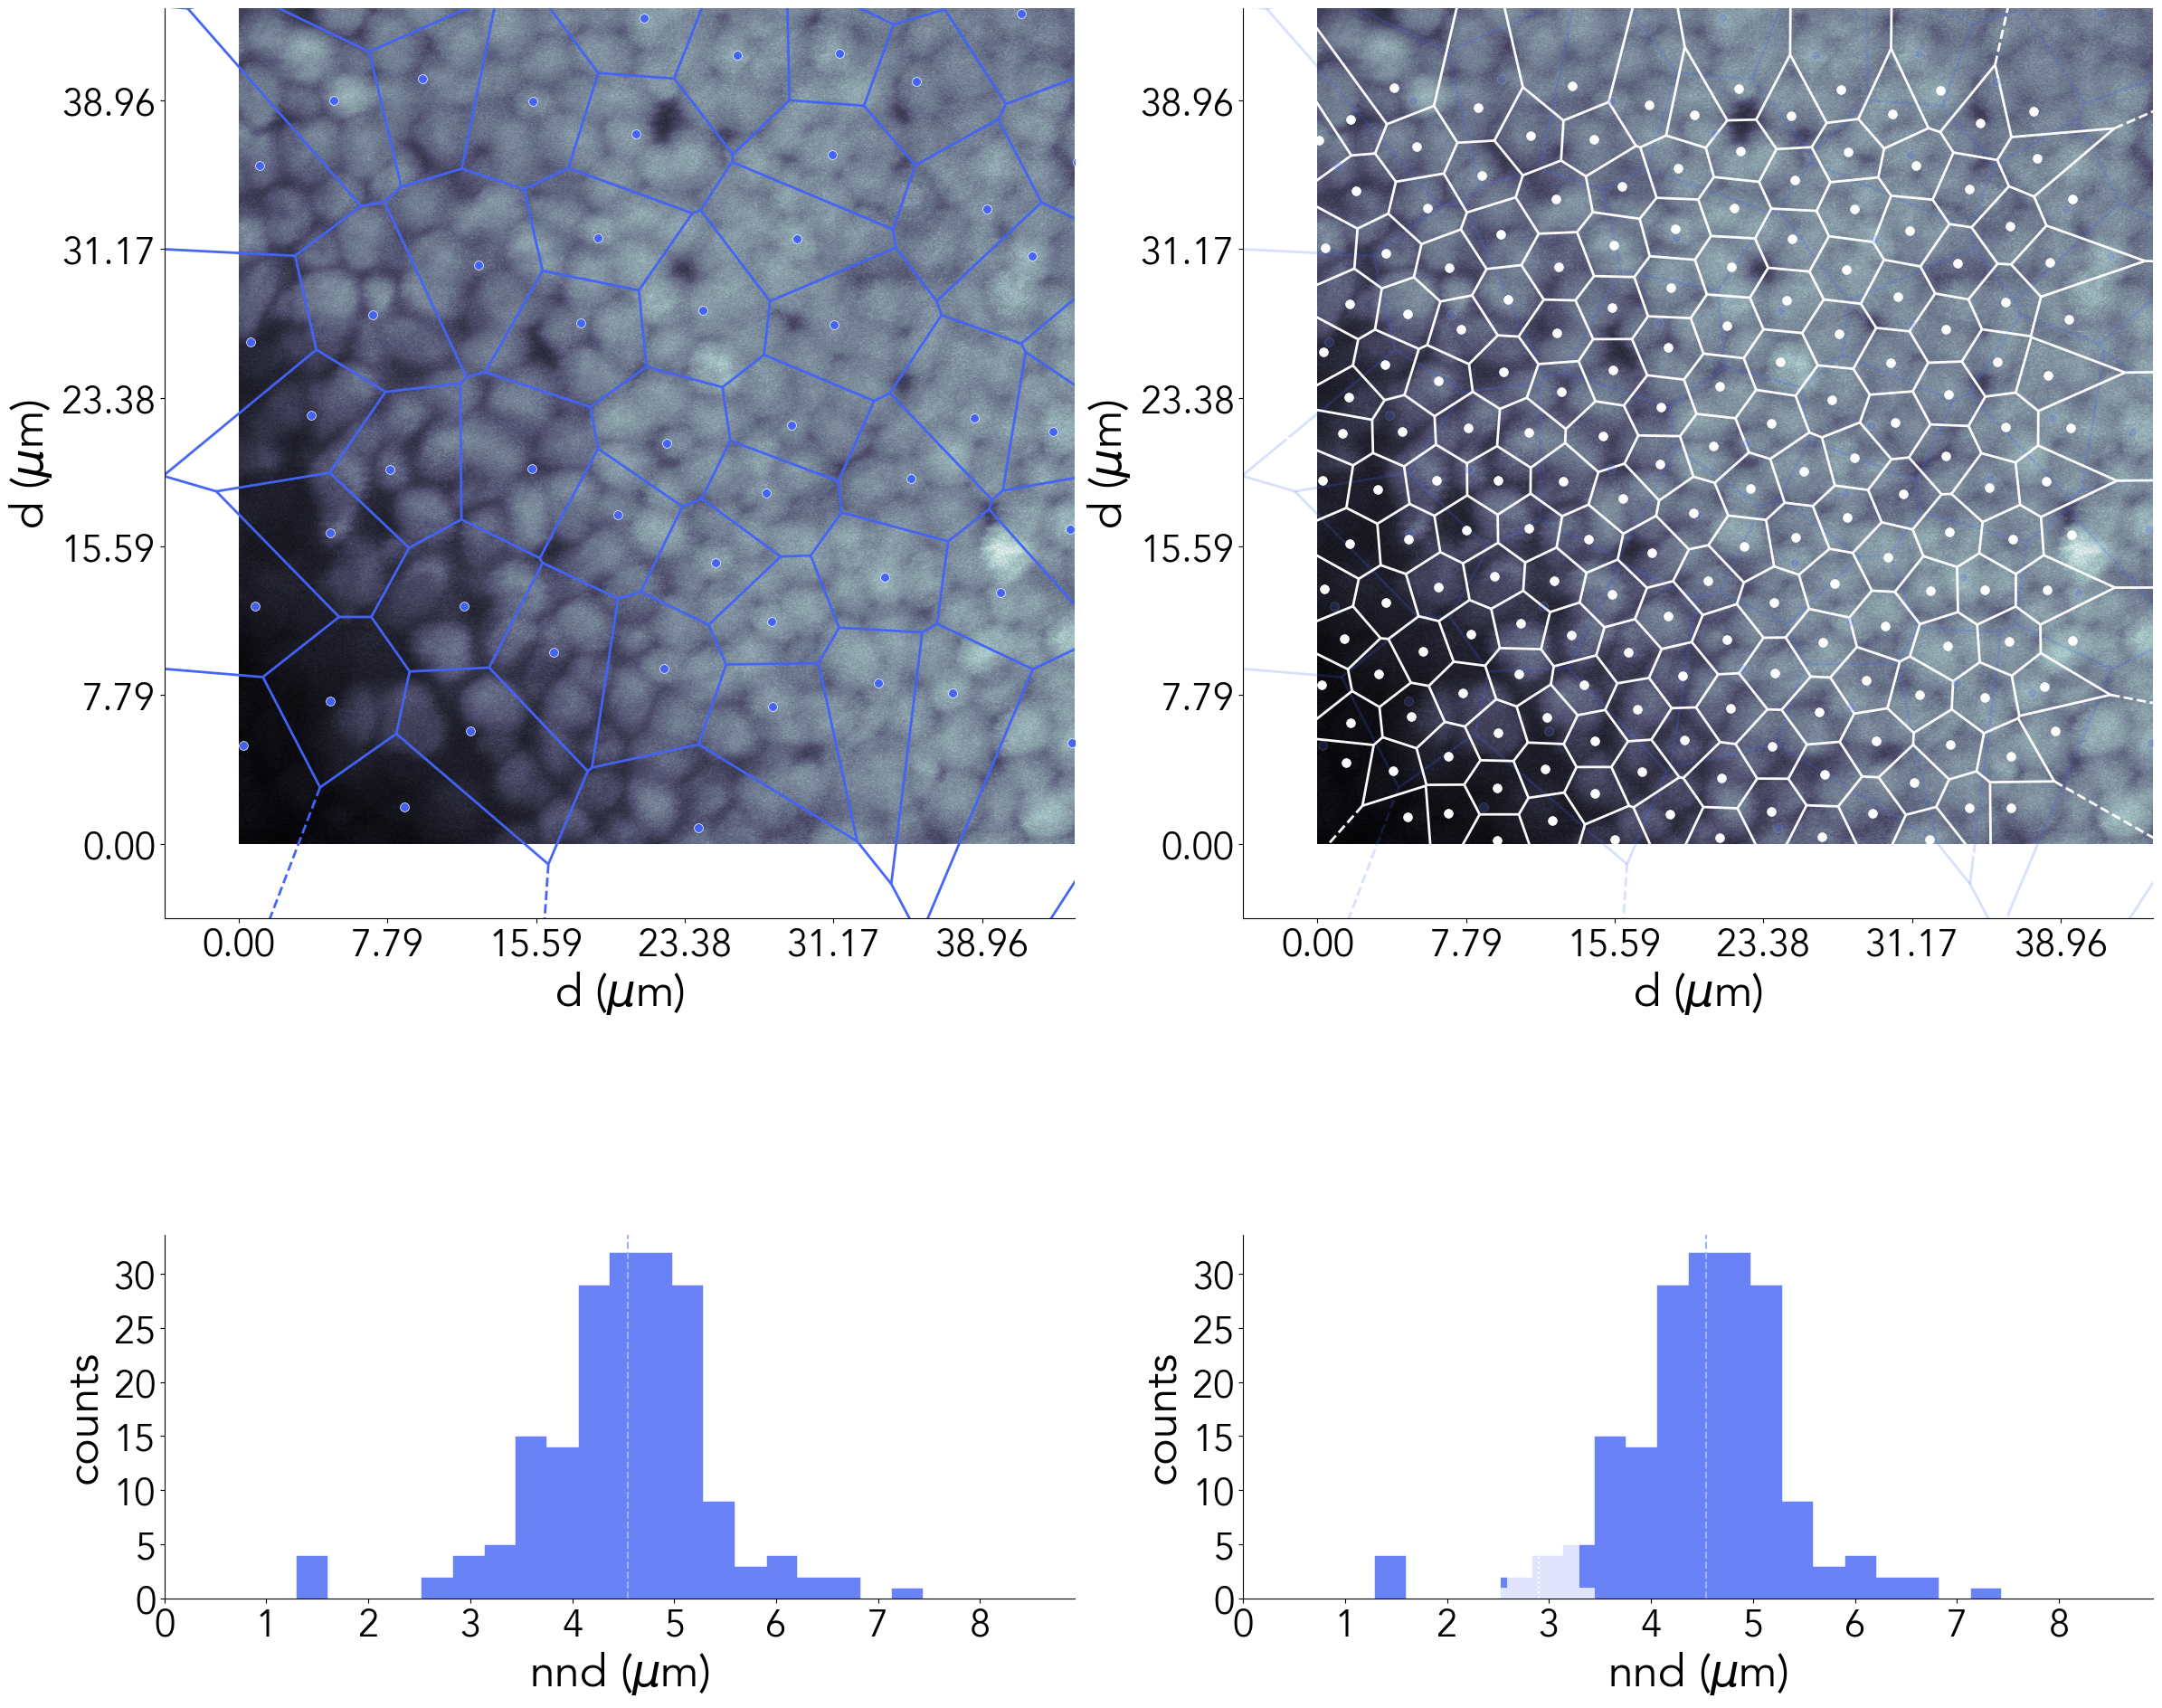

In [3]:
#WILDTYPE (FOU) FILES
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
        ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'S', datatype = 'labels', bg = 'S_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for S Cones
    
# #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/'
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', 
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', 
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'S', datatype = 'labels', bg = 'S_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for S Cones
    
# #TBX2A KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
        ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'M', datatype = 'labels', bg = 'M_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for M Cones
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'S', datatype = 'labels', bg = 'S_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for S Cones
     
    

nnd.plotAll();


## New NND Analysis with AXR Conversion 

In [8]:
import os
import numpy as np

P2UM = 79.64/2048  # um per pixel (AXR conversion)

def run_one(dPath, filepath, celltype, bg, nIter=1000, overwriteFlag=False, datatype='labels'):
    folder = dPath + filepath

    print(f"\n[{filepath}]")
    print(f"  Step: compute NND for celltype={celltype} (bg={bg})")
    obj = NNDcalculator(
        dPath=folder,
        celltype=celltype,
        datatype=datatype,
        bg=bg,
        nIter=nIter,
        saveLloyd=True,
        overwriteFlag=overwriteFlag
    )

    # median NND (raw) in pixels and um
    nnd_pix = np.asarray(obj.nnd, dtype=float).ravel()
    nnd_pix = nnd_pix[~np.isnan(nnd_pix)]
    nnd_med_pix = np.median(nnd_pix) if nnd_pix.size else np.nan
    nnd_med_um = nnd_med_pix * P2UM

    # RI values
    ri = float(getattr(obj, "ri", np.nan))
    iri = float(getattr(obj, "iri", np.nan))

    print(f"  Step: summary -> median NND = {nnd_med_pix:.6g} px = {nnd_med_um:.6g} um")
    print(f"  Step: RI computed -> RI(raw)={ri:.6g}, RI(Lloyd)={iri:.6g}")

    # confirm saved files exist
    fn_nnd = os.path.join(folder, f"{celltype}_nnd.npy")
    fn_ri  = os.path.join(folder, f"{celltype}_ri.npy")
    print(f"  Step: saved? {os.path.exists(fn_nnd)}  {celltype}_nnd.npy")
    print(f"  Step: saved? {os.path.exists(fn_ri)}   {celltype}_ri.npy")

    return obj


# -------------------------
# WILDTYPE (FOU) FILES
# -------------------------
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
# '20250425_2ahetinx_5d_m2G_s2C_L01_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L01_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L03_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L04_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L04_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L07_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L07_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L08_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L09_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L09_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L10_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L11_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L11_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L12_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L12_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L13_002/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L13_004/', #S NND DONE (CH 2026)
        # '20250425_2ahetinx_5d_m2G_s2C_L14_002/', #S NND DONE (CH 2026)
        # '20250716_5d_m2G_s2C_2ahetinx_L06_002/', #S NND DONE (CH 2026)
        # '20250716_5d_m2G_s2C_2ahetinx_L06_004/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/', #S NND DONE (CH 2026)
        # '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/', #S NND DONE (CH 2026)
        # '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/', #S NND DONE (CH 2026)
        # "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/", #S NND DONE (CH 2026)
        # "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/", #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/', #S NND DONE (CH 2026) 
        # # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/', #no M seg curated
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',  #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/', #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' , #S NND DONE (CH 2026)
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/', #S NND DONE (CH 2026)
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/', #S NND DONE (CH 2026)
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/', #S NND DONE (CH 2026)
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/', #S NND DONE (CH 2026)
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
]

print("\n==================== WT ====================")
for filepath in fPath:
    _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
    _ = run_one(dPath, filepath, celltype='S', bg='S_mip', nIter=1000, overwriteFlag=False)


# -------------------------
# TBX2B KO FILES
# -------------------------
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/' NO M SEG - COMEBACK FOR THIS ONE
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', 
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', 
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
]

print("\n==================== tbx2b_KO ====================")
for filepath in fPath:
    _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
    _ = run_one(dPath, filepath, celltype='S', bg='S_mip', nIter=1000, overwriteFlag=False)


# -------------------------
# TBX2A KO FILES
# -------------------------
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
]

print("\n==================== tbx2a_KO ====================")
last_obj = None
for filepath in fPath:
    _ = run_one(dPath, filepath, celltype='M', bg='M_mip', nIter=1000, overwriteFlag=False)
    last_obj = run_one(dPath, filepath, celltype='S', bg='S_mip', nIter=1000, overwriteFlag=False)

# Optional: plot the last one (matches your original behavior)
last_obj.plotAll()


==================== WT ====================

[20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/]
  Step: compute NND for celltype=M (bg=M_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/
  Step: summary -> median NND = 101.165 px = 3.93397 um
  Step: RI computed -> RI(raw)=4.48142, RI(Lloyd)=9.59573
  Step: saved? True  M_nnd.npy
  Step: saved? True   M_ri.npy

[20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/]
  Step: compute NND for celltype=S (bg=S_mip)
Loaded saved Lloyd relaxation
Saved results for Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/
  Step: summary -> median NND = 110.445 px = 4.29485 um
  Step: RI computed -> RI(raw)=4.58932, RI(Lloyd)=8.23125
  Step: saved? True  S_nnd.npy
  Step: saved? True   S_ri.npy

[20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/]
  Step: compute NND for celltype=M (bg=M_mip)


ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

Error in callback <function _draw_all_if_interactive at 0x000001BBFC6D1D30> (for post_execute):


ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

ValueError: 
d ($$\mu$$m)
   ^
ParseException: Expected end of text, found '$'  (at char 3), (line:1, col:4)

<Figure size 2400x2400 with 4 Axes>

## Plot individual retinas

In [17]:
!jupyter labextension list

JupyterLab v3.6.1
C:\Users\Carin\mambaforge\envs\cellCounting\share\jupyter\labextensions
        ipycanvas v0.13.1 enabled ok
        ipyevents v2.0.1 enabled ok
        jupyterlab-jupytext v1.3.8+dev enabled ok (python, jupytext)
        jupyterlab_pygments v0.2.2 enabled ok (python, jupyterlab_pygments)
        @jupyter-widgets/jupyterlab-manager v5.0.5 enabled ok (python, jupyterlab_widgets)



In [24]:
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/" #wildtype 
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/" #2a mutants
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/" #2b mutants 
fList = sorted([f for f in os.listdir(dPath) if not f.startswith('.')])

fLabel = ipywidgets.widgets.Label('Select filepath', layout=ipywidgets.Layout(width='10%', height='40px'))
fMenu = ipywidgets.Dropdown(options=fList,value=fList[0],disabled=False,layout=ipywidgets.Layout(width='30%', height='40px'))
fButton = ipywidgets.Button(description='plotNDD',disabled=False,button_style='',tooltip='plotNDD',
                            icon='check',layout=ipywidgets.Layout(width='20%', height='40px'))
fOut = ipywidgets.Output(layout=ipywidgets.Layout(width='40%', height='40px'))
def on_button_clicked(b):
    with fOut:
        fOut.clear_output()
        fPath = fMenu.value
        print(fPath)
fButton.on_click(on_button_clicked)
fSelect = ipywidgets.widgets.HBox([fLabel,fMenu,fButton,fOut])
fSelect

C:\Users\Carin\pythonCode\lloyd.py:503: UserWarning: Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/M_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


TypeError: list indices must be integers or slices, not tuple

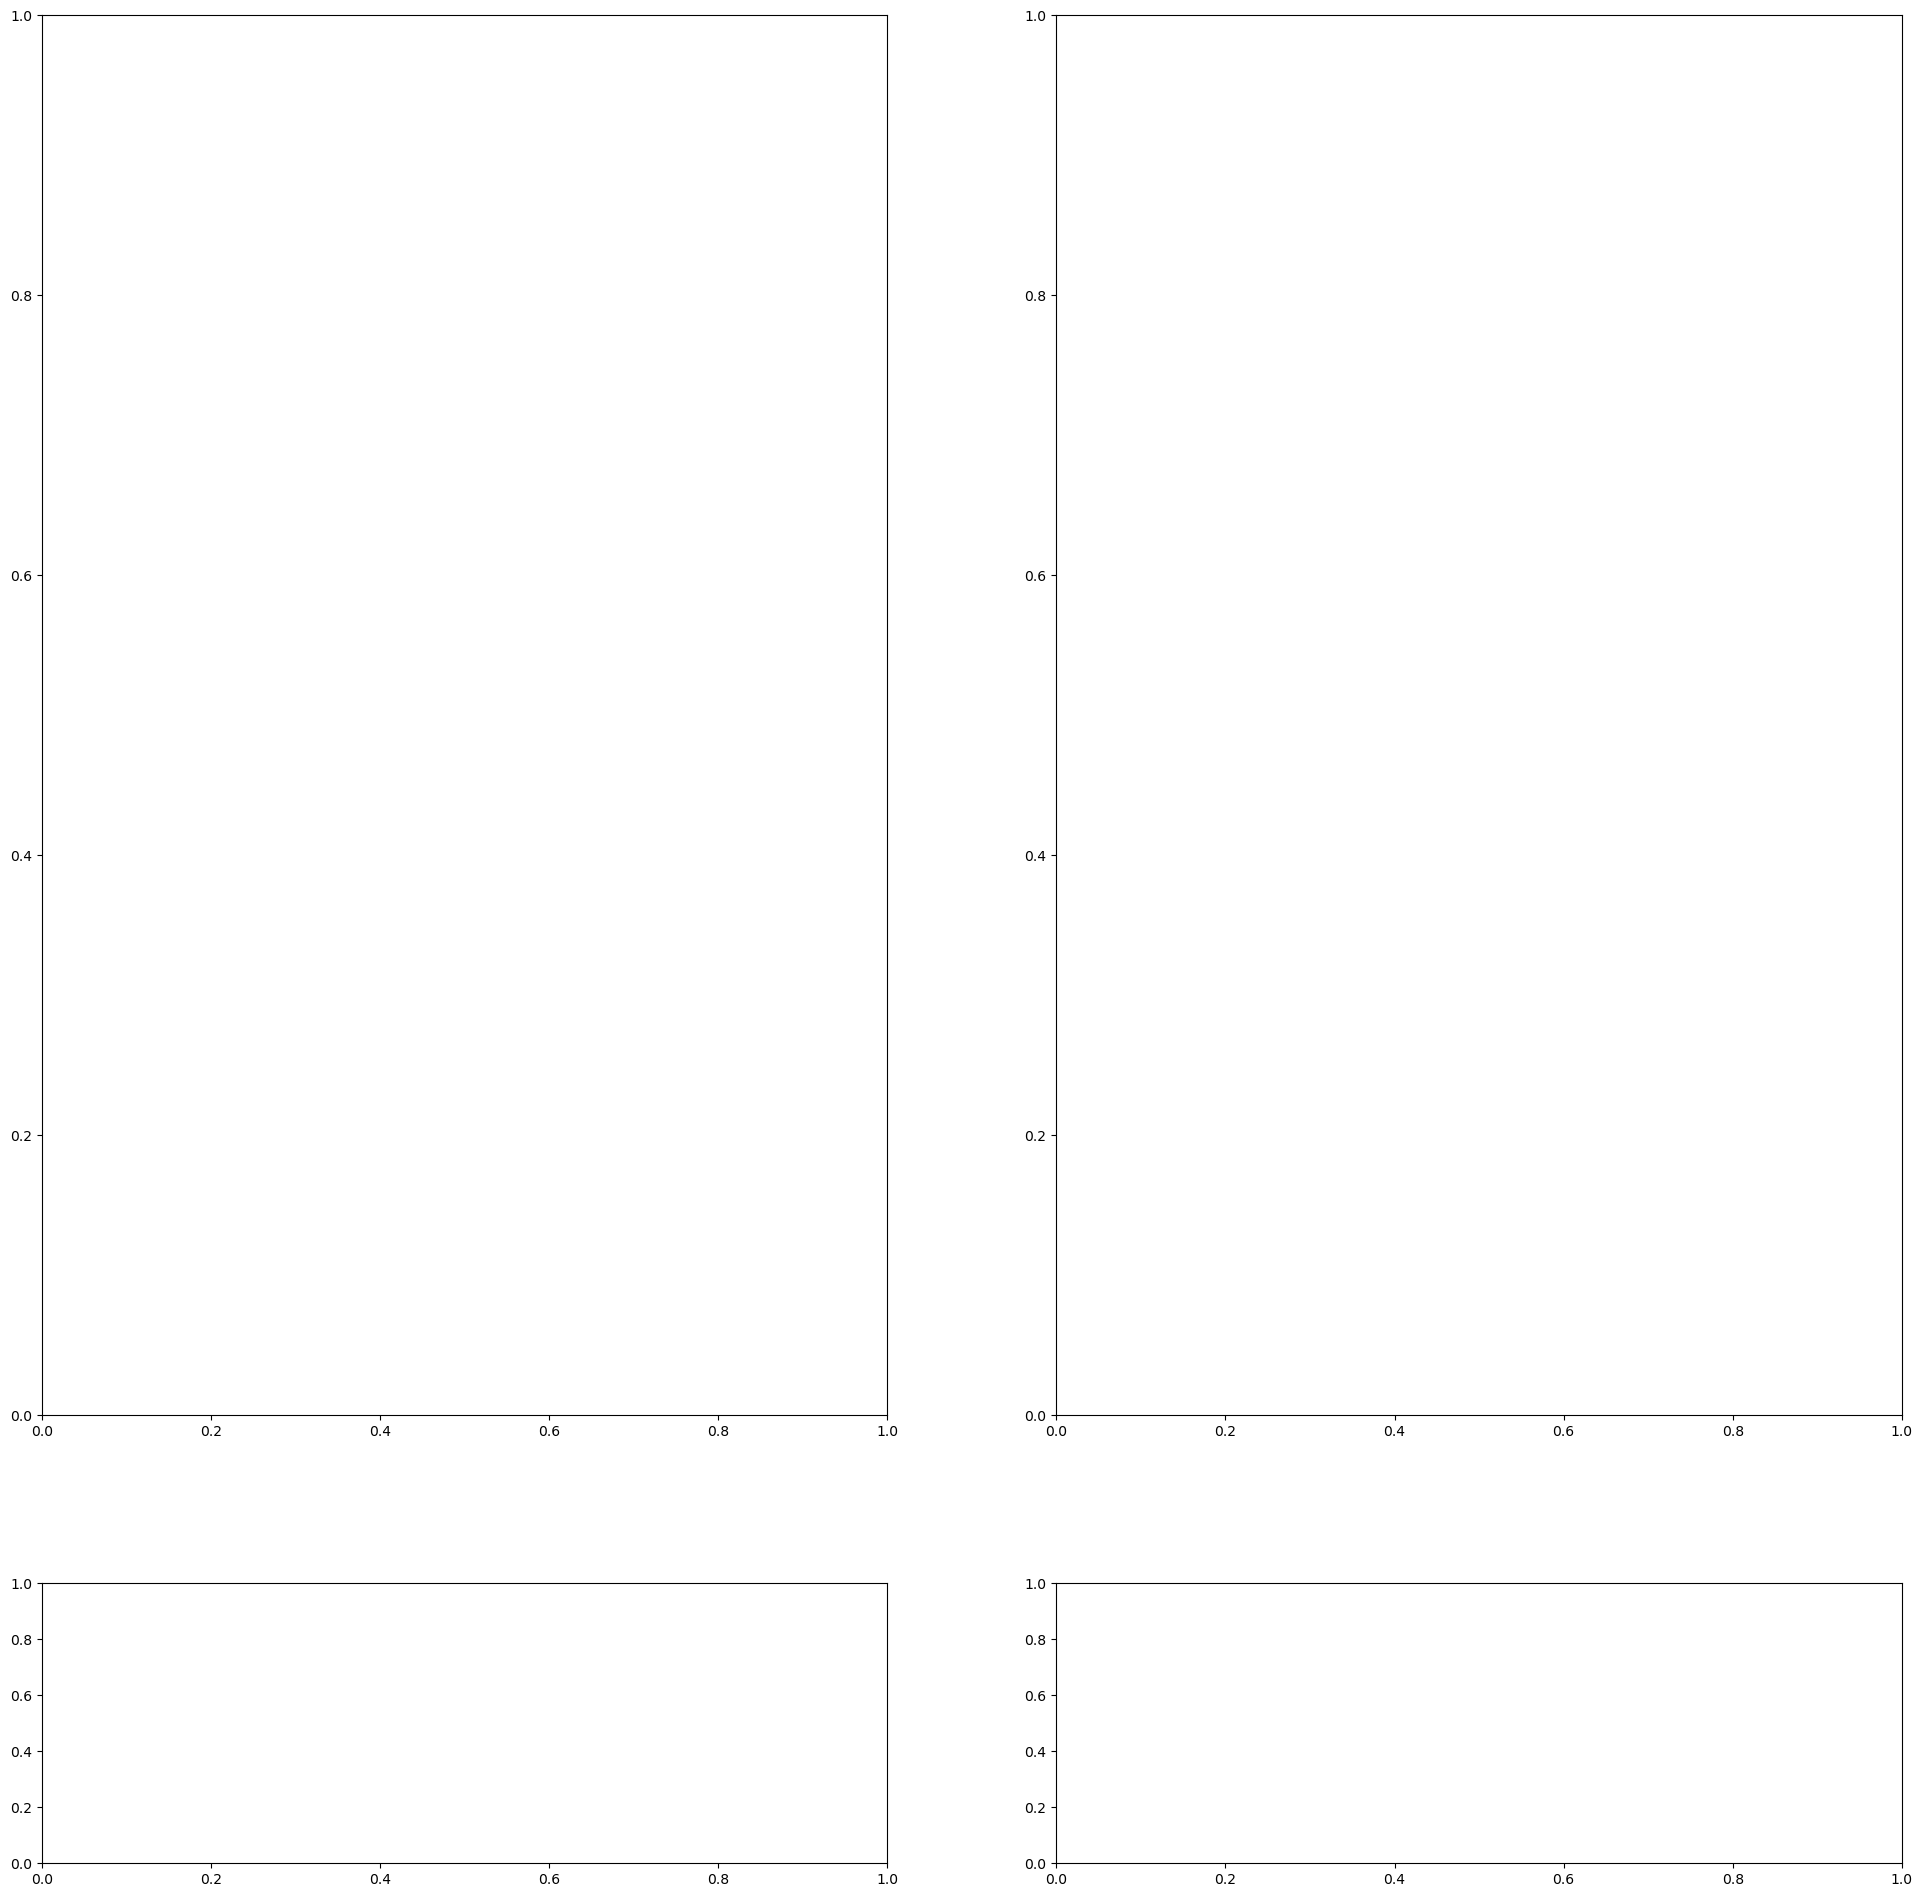

In [18]:
fPath = fMenu.value + '/'
ndd = NNDcalculator(dPath = dPath + fPath, celltype = 'M', datatype = 'labels', bg = 'M_mip')
ndd.plotAll();


In [ ]:

# dAnalysis = "/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/"
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L03_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L04_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L10_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L10_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L11_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L12_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L13_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L13_004/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L15_002/' # incomplete dotting
#### fPath = '20220121_5dpf_xOG_aCT_wt_L16_002/' # incomplete dotting

ndd = NNDcalculator(dPath = dPath + fPath)
ndd.plotAll();


In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_002/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_004/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L03_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_004/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L12_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L15_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L16_002/'

dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/' # 2 UV cone missing clearly disrupt pattern
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/' # 1 UV cone missing
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/' # some missing in corner
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/'

ndd2 = NNDcalculator(dPath = dPath + fPath)
ndd2.plotAll();


## Collect NDD distributions across cells

### F&empty;[_nr2e3_]

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = [
    '20220121_5dpf_xOG_aCT_wt_L01_002/',
    '20220121_5dpf_xOG_aCT_wt_L02_002/',
    '20220121_5dpf_xOG_aCT_wt_L02_004/',
    '20220121_5dpf_xOG_aCT_wt_L03_002/',
    '20220121_5dpf_xOG_aCT_wt_L04_002/',
    '20220121_5dpf_xOG_aCT_wt_L05_002/',
    '20220121_5dpf_xOG_aCT_wt_L06_002/',
    '20220121_5dpf_xOG_aCT_wt_L07_002/',
    '20220121_5dpf_xOG_aCT_wt_L07_004/',
    '20220121_5dpf_xOG_aCT_wt_L08_002/',
    '20220121_5dpf_xOG_aCT_wt_L08_004/',
    '20220121_5dpf_xOG_aCT_wt_L09_002/',
    '20220121_5dpf_xOG_aCT_wt_L10_002/',
    '20220121_5dpf_xOG_aCT_wt_L11_004/',
    '20220121_5dpf_xOG_aCT_wt_L12_002/',
    '20220121_5dpf_xOG_aCT_wt_L13_004/',
]
nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    # ndd = NNDcalculator(dPath = dPath + filepath)
    nnd = np.load(dPath + filepath + 'nndU.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = [
    '20220121_5dpf_xOG_aCT_nr2e3_L01_002/', # there's one UV cone not dotted that skews things
    '20220121_5dpf_xOG_aCT_nr2e3_L01_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L02_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L03_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L05_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L06_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L06_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L07_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L08_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L08_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L09_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L09_004/',
    '20220121_5dpf_xOG_aCT_nr2e3_L10_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L10_004/', # there's one UV cone not dotted that skews things
    '20220121_5dpf_xOG_aCT_nr2e3_L12_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L15_002/',
    '20220121_5dpf_xOG_aCT_nr2e3_L16_002/',
]

nndUMean_nr2e3 = np.empty((len(fPath),1))
nndUMean_nr2e3[:]=np.NaN
i=0;
for filepath in fPath:
    # ndd = NNDcalculator(dPath = dPath + filepath)
    nnd = np.load(dPath + filepath + 'nndU.npy')
    nndUMean_nr2e3[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = [
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/',
]
nndUMean_nr2f1b = np.empty((len(fPath),1))
nndUMean_nr2f1b[:]=np.NaN
i=0;
for filepath in fPath:
    # ndd = NNDcalculator(dPath = dPath + filepath)
    nnd = np.load(dPath + filepath + 'nndU.npy')
    nndUMean_nr2f1b[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_nr2e3,nndUMean_nr2f1b],['#888888','#BF141B','#8888BB'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','F0[nr2e3]','F0[nr2f1b]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median UVndd  (um)', fontproperties=fontLabels)
plt.show()

### F&empty;[_tbx2a_:Tbx2a-Halo] in Nalou & Fou

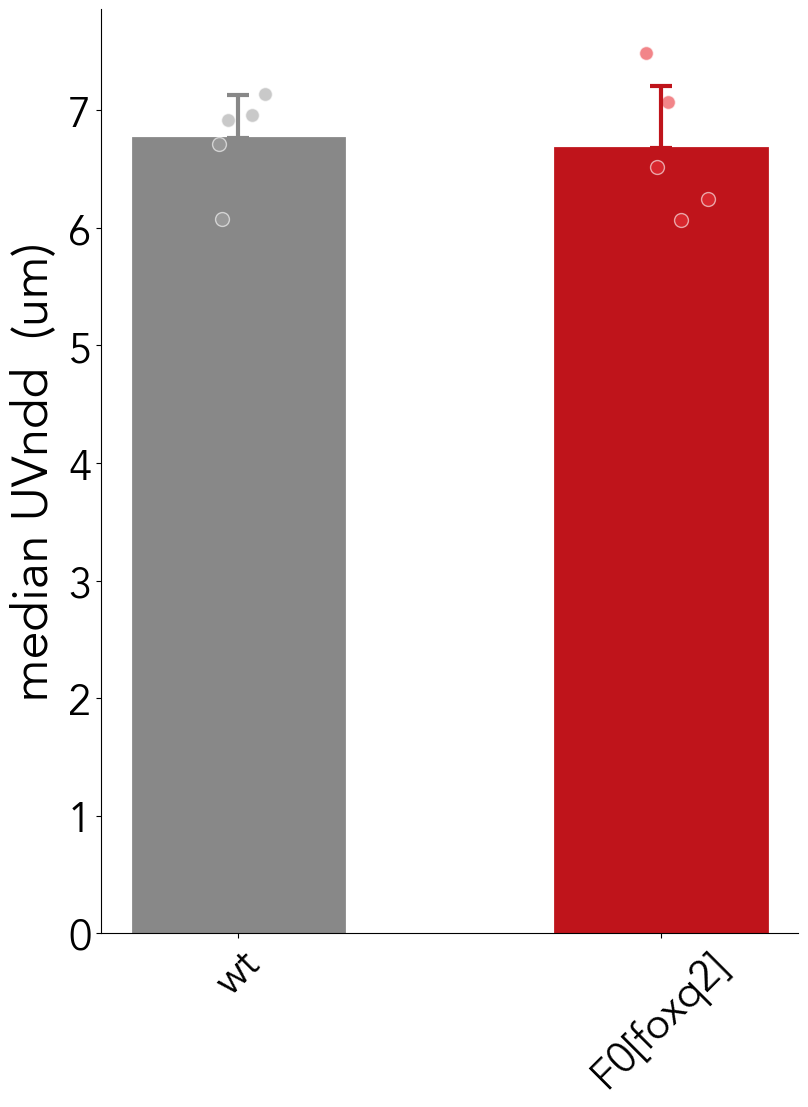

In [29]:
celltype = 'U'

#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002',
        '20250425_2ahetinx_5d_m2G_s2C_L04_004',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004'
]


nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

    #injectedrescue    
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002'
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_005',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004',
]

nndUMean_foxq2 = np.empty((len(fPath),1))
nndUMean_foxq2[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_foxq2[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_foxq2],['#888888','#BF141B'],['o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]);
axH.set_xticklabels(['wt','F0[foxq2]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median UVndd  (um)', fontproperties=fontLabels)
plt.show()

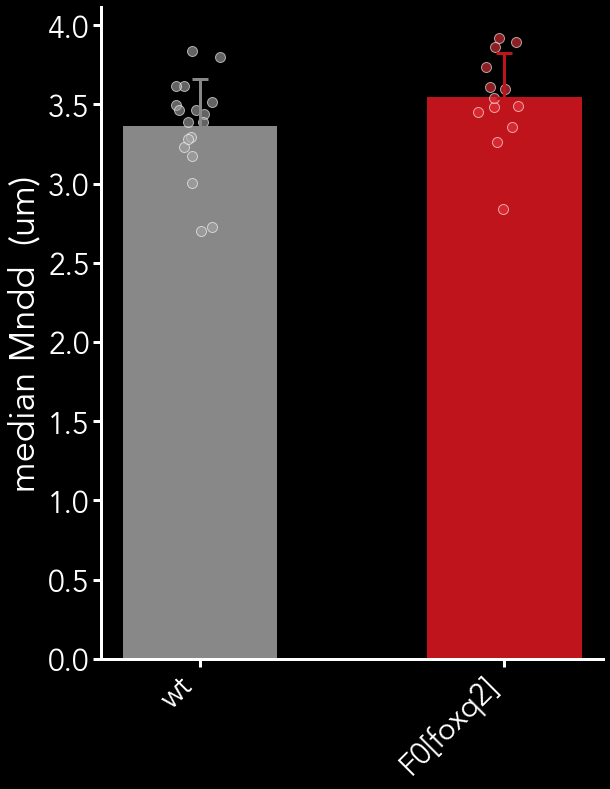

In [30]:





celltype = 'M'

dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRfoxq2F0/mw2Gt2T/wt/'
fPath = [
'20210716_5dpf_m2G_t2T_uninj_L101b/',
'20210716_5dpf_m2G_t2T_uninj_L101d/',
'20210716_5dpf_m2G_t2T_uninj_L102b/',
'20210716_5dpf_m2G_t2T_uninj_L103b/',
'20210716_5dpf_m2G_t2T_uninj_L103d/',
'20210716_5dpf_m2G_t2T_uninj_L104b/',
'20210716_5dpf_m2G_t2T_uninj_L104d/',
'20210716_5dpf_m2G_t2T_uninj_L105b/',
'20210716_5dpf_m2G_t2T_uninj_L106b/',
'20210716_5dpf_m2G_t2T_uninj_L106d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L01b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L03b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L03d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L05b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L05d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L12b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L12d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L14b/',
]


nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

dPath = 'D:/Analysis/F0Tbx2arescueHalo_20241003/s1CxOG/inj2arescue/'
fPath = [
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L01b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L01d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L02b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L02d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L03b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L03d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L04b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L05b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L05d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L06b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L06d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L07b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L07d/',
]


nndUMean_foxq2 = np.empty((len(fPath),1))
nndUMean_foxq2[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_foxq2[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_foxq2],['#888888','#BF141B'],['o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]);
axH.set_xticklabels(['wt','F0[foxq2]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  (um)'.format(celltype), fontproperties=fontLabels)
plt.show()

## Plotting S NND Barplots 

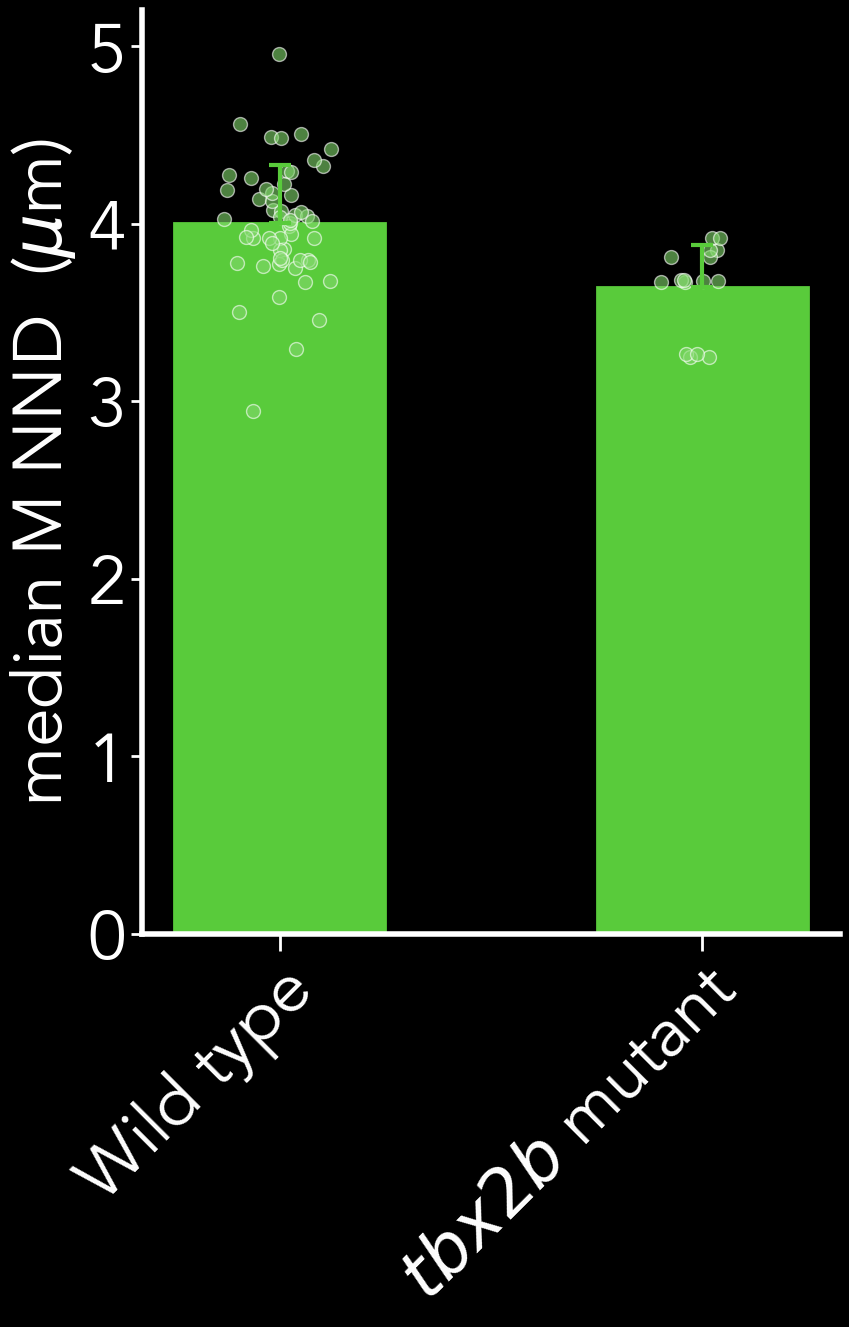

In [17]:

celltype = 'M'
# celltype = 'S'


#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002/', 
        '20250425_2ahetinx_5d_m2G_s2C_L04_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/', #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/',  #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
            ]

nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

 #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',  
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', 
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #missing nnd? 
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with S/M nnd
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/', 
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005', (UNCOMMENTED?)
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002', (UNCOMMENTED?)
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        ]

nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
#Only use the M and S combo for S cone spacing!!!!! 
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
        ] 

nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
# for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2b,nndUMean_tbx2a],['#4669F2','#4669F2','#4669F2'],['o','o','o']): #use for S cones 
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2b],['#59cb3bff','#59cb3bff'],['o','o']): #use for M cones - 1 mutant
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4)    
    
    
fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]); #Manually Update for 1 mutant! 
axH.set_xticklabels(['Wild type','$\it{tbx2b}$ mutant'], ha='right', rotation_mode='anchor'); #use for 1 mutant 
# axH.set_xticklabels(['Wild type','$\it{tbx2b}$ mutant','$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor');  #use for both mutants 
axH.xaxis.set_tick_params(rotation=45, length=12) #adjust rotation and length of ticks (x axis) 

axH.tick_params(axis='x', labelsize=50)  # x tick labels size
axH.tick_params(axis='y', labelsize=50)  # y tick labels size 

# axH.set_ylim([0,9]); # tbx2
axH.tick_params(axis='both', which='major', width=2) #adjust thickness of tick marks 

# axH.set_ylabel('median {0}ndd  ($\mu$m)'.format(celltype), fontsize=50)
# axH.set_ylabel('median S NND  ($\mu$m)'.format(celltype), fontsize=50) #use for S cones 
axH.set_ylabel('median M NND  ($\mu$m)'.format(celltype), fontsize=50) #use for M cones 


axH.yaxis.set_tick_params(length=8) #adjust length of tick mark (y axis)


plt.style.use('dark_background') #Dark background
# plt.style.use('default')  # White background

plt.show()


# Stats on S NND

In [10]:
#STATS on S NND! 

import numpy as np
from scipy.stats import kruskal
import scikit_posthocs

# Example: you computed these earlier for celltype = 'L'
# nndUMean_wt, nndUMean_tbx2a (Tbx2bKO), nndUMean_tbx2b (Tbx2aKO)

nnd_by_pr = {
    'M': {
        'wt': np.ravel(nndUMean_wt),
        'tbx2b_KO': np.ravel(nndUMean_tbx2b),  # NOTE: your variable name is swapped
        'tbx2a_KO': np.ravel(nndUMean_tbx2a),
    },
    # If you also computed M:
    # 'M': {'wt': ..., 'tbx2b_KO': ..., 'tbx2a_KO': ...}
}


geneList = ['wt', 'tbx2b_KO', 'tbx2a_KO']
photoreceptors = ['M']  # keep only those you actually have in nnd_by_pr

for pr in photoreceptors:
    wtCount = nnd_by_pr[pr]['wt']
    tbx2bKOCount = nnd_by_pr[pr]['tbx2b_KO']
    tbx2aKOCount = nnd_by_pr[pr]['tbx2a_KO']

    # drop NaNs
    wtCount = wtCount[~np.isnan(wtCount)]
    tbx2bKOCount = tbx2bKOCount[~np.isnan(tbx2bKOCount)]
    tbx2aKOCount = tbx2aKOCount[~np.isnan(tbx2aKOCount)]

    h, p = kruskal(wtCount, tbx2bKOCount, tbx2aKOCount)

    print(f'\nFor {pr} NND medians:')
    print('\t\tH = {0:.3f}, p = {1:.20f}, nEyes: wt = {2:.0f}; {3} = {4:.0f}; {5} = {6:.0f}'.format(
        h, p, len(wtCount), geneList[1], len(tbx2bKOCount), geneList[2], len(tbx2aKOCount)
    ))

    posthoc_names = ['wt', 'tbx2b_KO', 'tbx2a_KO']
    r = scikit_posthocs.posthoc_conover(
        [wtCount, tbx2bKOCount, tbx2aKOCount],
        p_adjust='Bonferroni'
    )

    print('\tConover-Iman posthoc + Bonferroni p adjustment:')
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[0], posthoc_names[1], r.iloc[0,1]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[0], posthoc_names[2], r.iloc[0,2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[1], posthoc_names[2], r.iloc[1,2]))



For M NND medians:
		H = 16.652, p = 0.00024217234919317359, nEyes: wt = 56; tbx2b_KO = 16; tbx2a_KO = 1
	Conover-Iman posthoc + Bonferroni p adjustment:
		wt vs. tbx2b_KO: p = 0.00005876564388932409 | p = 5.8765643889324086e-05
		wt vs. tbx2a_KO: p = 1.00000000000000000000 | p = 1.0
		tbx2b_KO vs. tbx2a_KO: p = 0.65666102566803574714 | p = 0.6566610256680357


## Save as SVG to G-drive/NAS 
> Remember to update filename! 

In [18]:
import os
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
outdir = r"Y:/2026_TBX2Tornado/Fig2_Misexpression_SCones/DarkPanels"


fname = f"TBX2KO_M_NND_Dark.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


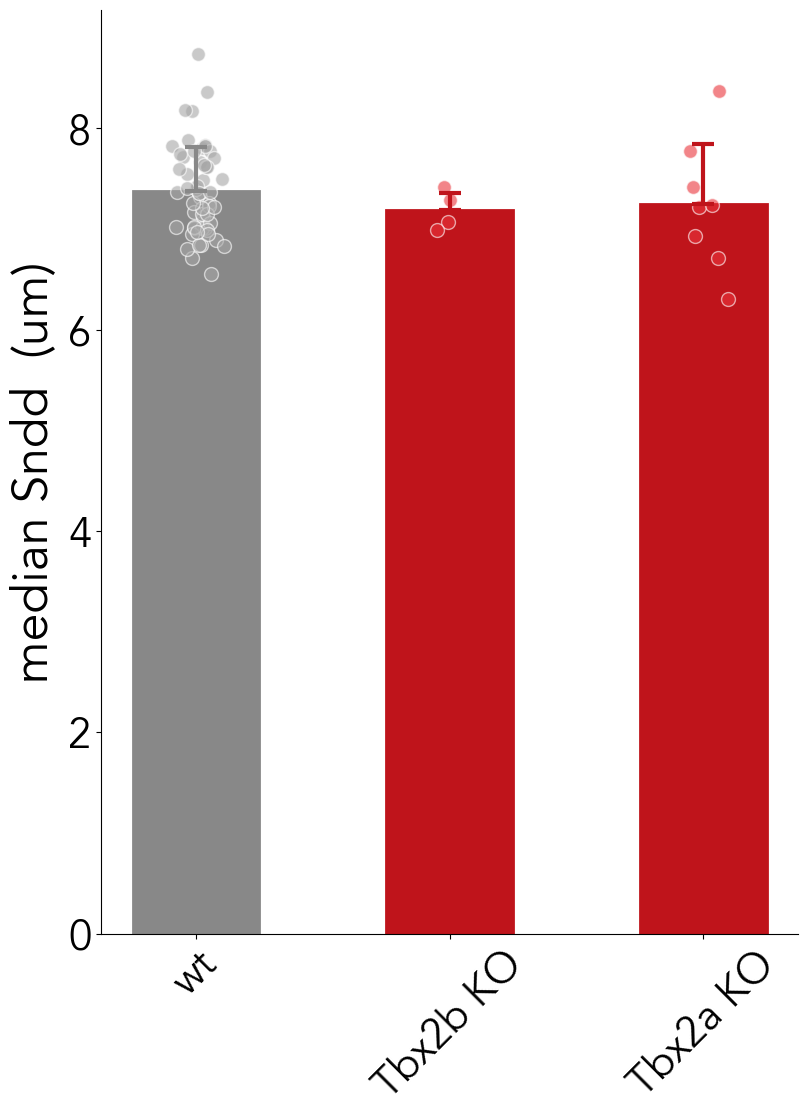

In [42]:

celltype = 'S'

#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002/', 
        '20250425_2ahetinx_5d_m2G_s2C_L04_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/', #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/',  #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
            ]

nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

 #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
# '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002'#issue with M nnd 
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with M nnd
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        ]

nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
        ] 

nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2a,nndUMean_tbx2b],['#888888','#BF141B','#BF141B'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','Tbx2b KO','Tbx2a KO']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  (um)'.format(celltype), fontproperties=fontLabels)
plt.show()


#### Violin plots

TypeError: 'AxesSubplot' object is not subscriptable

Text(0, 0.5, 'Rndd  (um)')

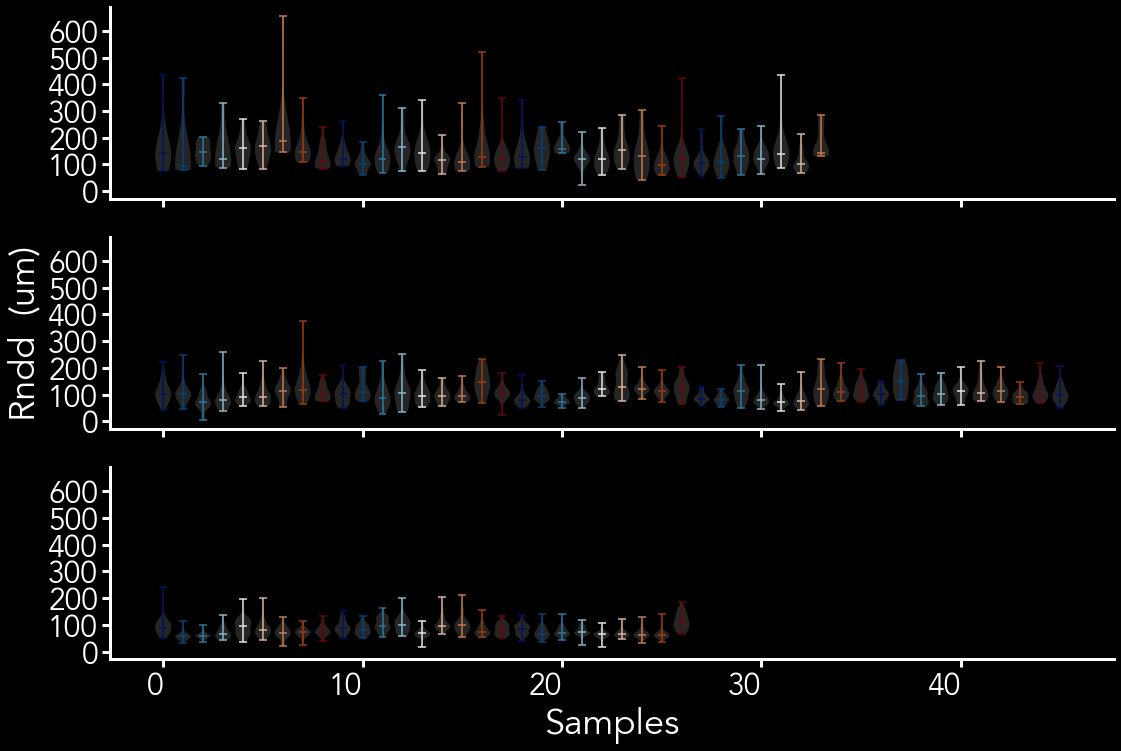

In [281]:
celltype = 'R'


plotname = ''
fH, axH = plt.subplots(3,1,figsize= [18,12], sharey=True, sharex = True)


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/wt/'
fPath = [
'20200821_5dpf_xOG_s1mCh_uninj_i05b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i05d/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06d/',
'20200821_5dpf_xOG_s1mCh_uninj_i101b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i101d/',
'20200821_5dpf_xOG_s1mCh_uninj_i102b/',
'20200821_5dpf_xOG_s1mCh_uninj_i103b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104d/',
'20201113_5dpf_xOG_s1mCh_uninj_i06b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12d/',
'20201113_5dpf_xOG_s1mCh_uninjected_i13b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15d/',
'20210514_5dpf_xOG_s1C_uninj_L01b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L05b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L07b_withDAPI/',
'20221026_5dpf_xOG_s1C_wt_L01_002/',
'20221026_5dpf_xOG_s1C_wt_L01_004/',
'20221026_5dpf_xOG_s1C_wt_L02_002/',
'20221026_5dpf_xOG_s1C_wt_L03_002/',
'20221026_5dpf_xOG_s1C_wt_L03_004/',
'20221026_5dpf_xOG_s1C_wt_L04_002/',
'20221026_5dpf_xOG_s1C_wt_L04_004/',
'20221026_5dpf_xOG_s1C_wt_L05_002/',
'20221026_5dpf_xOG_s1C_wt_L05_004/',
'20221026_5dpf_xOG_s1C_wt_L06_002/',
# '20221026_5dpf_xOG_s1C_wt_L07_002/',
'20221026_5dpf_xOG_s1C_wt_L07_004/',
'20221026_5dpf_xOG_s1C_wt_L08_002/',
'20221026_5dpf_xOG_s1C_wt_L08_004/',
'20221026_5dpf_xOG_s1C_wt_L09_002/',
'20221026_5dpf_xOG_s1C_wt_L09_004/',
'20221026_5dpf_xOG_s1C_wt_L10_002/',
'20221026_5dpf_xOG_s1C_wt_L10_004/',
'20221026_5dpf_xOG_s1C_wt_L11_002/',
'20221026_5dpf_xOG_s1C_wt_L12_002/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[0].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2a/'
fPath = [
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L01b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L02b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L03b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L04b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L05b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L06b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L09b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L10b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L12b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L14b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L15b/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L03_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_004/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[1].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;

    
dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2b/'
fPath = [
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i09b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13d/',
# '20201113_5dpf_xOG_s1mCh_CRtbx2b_i14b/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_004/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_002/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L12_002/',
]    

i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


    
    
fontLabels = formatFigureMain(fH, axH[0], pH)
fontLabels = formatFigureMain(fH, axH[1], pH)
fontLabels = formatFigureMain(fH, axH[2], pH)
axH[2].set_xlabel('Samples', fontproperties=fontLabels)
axH[1].set_ylabel('{0}ndd  (um)'.format(celltype), fontproperties=fontLabels)

In [245]:

    
# vp[i] = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=False, showmedians=True)

SyntaxError: invalid syntax (987083096.py, line 1)

IndexError: list index out of range

# NDD on other photoreceptors (from labels layers)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
lPath = 'R_seg_curated.tiff'

labelData = imread(dPath + fPath + lPath)
# labelData

centroidData = calculateCentroidsFromLabels(labelData)
centroidData

In [ ]:
fH, axH = plt.subplots(figsize= [16,16])


pH = axH.imshow(labelData, cmap='bone')
pH = axH.scatter(centroidData[:,0],centroidData[:,1], color=zfC['R'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);

## <a id='voronoi'>Voronoi</a>
Nice visualization, not extremely useful by itself


> [Back to index](#Index)

In [ ]:
np.size(vorU.regions[1])

In [ ]:
dPath = "/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/photoArrays/"
fUName = "U_missing.csv"
fNName = "N_points.csv"
nucsTiff = '20220121_5dpf_xOG_aCT_nr2e3_L06_004' + '.tiff'


Nucs = plt.imread(dPath + nucsName)

df =  pd.read_csv(dPath + fUName)
df = df.drop(columns = 'index')
U=df.to_numpy()
U = U[:,[1,0]]
vorU = scipy.spatial.Voronoi(U)

df =  pd.read_csv(dPath + fNName)
df = df.drop(columns = 'index')
N=df.to_numpy()
N = N[:,[1,0]]
vorN = scipy.spatial.Voronoi(N)

vorN = scipy.spatial.Voronoi(np.append(U,N,axis=0))

plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

pH = axH.imshow(imread(dPath + nucsTiff), cmap='bone')


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.6, point_size=2)


regions, vertices = voronoi_finite_polygons_2d(vorU)
# colorize
for region in regions:
    polygon = vertices[region]
    plt.fill(*zip(*polygon), alpha=0.1)
    
# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);

axH.set_xlim([-100,1124])
axH.set_ylim([-100,1124])

def p2umfx(x, pos): # formatter function
    s = '{:.2f}'.format(np.round(x * p2um,decimals=2))
    return s

axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))

# savePath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Manuscripts/2021_zfConeRNAseq/newGeneFigures/temp/'
# plt.savefig(savePath + goi + "_counts.svg", transparent=True, format="svg", bbox_inches = "tight")

### Lloyd's algorithm to make distribution more even
- Wikipedia: [Lloyd's algorithm](https://en.wikipedia.org/wiki/Lloyd%27s_algorithm)
- Implementation: [github.com/duhaime/lloyd](https://github.com/duhaime/lloyd)
    - Modified to use image boundaries (plus buffer) as mask for voronoi polygons during Lloyd's relaxation
    - Could use voronoi polygons to shapes or labels layers in napari [linkhere](https://napari.org/stable/gallery/shapes_to_labels.html)
        - there will be problems with vertices at infinity [someInforHere](https://stackoverflow.com/questions/23901943/voronoi-compute-exact-boundaries-of-every-region)
    

In [ ]:
# field = Field(np.multiply(np.ones(np.shape(U)),512)+np.random.normal(size=np.shape(U))) # start near the center and expand
field = Field(U, buffer = 20) #start from original locations of UV cones

nIterations = 2
with tqdm(total=nIterations, file=sys.stdout) as progBar:
# run Lloyd relaxation on the field of points
    for i in np.arange(0,nIterations):
        field.relax()
        progBar.update(1)



# get the resulting point positions
Ui = field.get_points()

vorUi = scipy.spatial.Voronoi(Ui)

# boundedRegions,boundedVertices = voronoi_finite_polygons_2d(vorUi)
# vorUi.regions = boundedRegions
# vorUi.vertices = boundedVertices


plotname = ''
fH, axH = plt.subplots(figsize= [16,16])


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.2, point_size=2)

pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)


border = [[0,0],[0,2048],[2048,2048],[2048,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')


regions, vertices = voronoi_finite_polygons_2d(vorUi)
clip = PolygonClipper()
# colorize
for region in regions:
    polygon = vertices[region]
    clipped = clip(polygon,border)
    plt.fill(*zip(*clipped), alpha=0.5)





# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);


axH.set_xlim([-1000,2124])
axH.set_ylim([-1000,2124])
    
    

In [ ]:
kdtUi = scipy.spatial.KDTree(Ui)
kN = 1
Uinnd = np.empty((len(Ui),kN))
Uinnd[:]=np.NaN



for n in range(0,len(Ui)):
    temp = kdtUi.query(Ui[n],kN+1)
    for k in range (0,kN):
        Uinnd[n,k] = temp[0][k+1]


plotname = ''
fH, axH = plt.subplots(figsize= [12,6])
    
for k in range (0,kN):
    pH = plt.hist(Unnd[:,k], bins=40, color=zfC['U'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);
    pH = plt.hist(Uinnd[:,k], bins=40, color=zfC['S'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);

axH.set_xlim([0,np.max((Unnd)*1.2)])

formatFigureMain(fH, axH, pH);
plt.show();

print ('\n')
for k in range (0,kN):
    print ('Median for {0}-NDD : {1:.2f} pixels'.format(k+1,np.median(Unnd[:,k])))
    print ('Median for {0}-NDD after Lloyd\'s relaxation : {1:.2f} pixels'.format(k+1,np.median(Uinnd[:,k])))

In [ ]:
U = nnd.Centroids
vorU = nnd.vor

#### Clipping polygon example

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

# pH = axH.imshow(Nucs, cmap='bone')

pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.8, point_size=2)

# pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
# pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)

# polygon = vorUi.vertices[vorUi.regions[24]]
# polygon = field.voronoi.vertices[field.voronoi.regions[30]+field.voronoi.regions[0]]
polygon = field.voronoi.vertices[field.voronoi.regions[12]]
plt.fill(*zip(*polygon),alpha=0.5,facecolor='r',edgecolor='k')


border = field.get_bb_pointsClockwise()
# border = [[0,0],[0,1024],[1024,1024],[1024,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')

clip = PolygonClipper()
clipped = clip(polygon,border)

plt.fill(*zip(*clipped),alpha=0.5,facecolor='g')

axH.set_xlim([-200,1200])
axH.set_ylim([-200,1200])